# XGBoost

**Inteligencia Artificial Aplicada (1INF62) — Pontificia Universidad Católica del Perú, 2026-2**

**Integrantes:** Aguilera, Jair · Araujo, Luis · Condori, Nilton · Vilcayauri, Pedro

---

### Abstract

Este notebook entrena un clasificador **XGBoost** (*eXtreme Gradient Boosting*), el modelo con mejor desempeño global en Ranjbar et al. (2023). Como el Random Forest, combina muchos árboles de decisión, pero no los entrena por separado: los entrena uno tras otro, y cada árbol nuevo corrige los errores que dejaron los anteriores (*boosting*). Así puede capturar relaciones no lineales e interacciones entre variables sin especificarlas. Usa las 9 features del EDA, casos completos y la partición temporal. La profundidad de los árboles, el peso mínimo de las hojas y el balanceo de clases se eligen por AUC-PR en validación, y el número de árboles con *early stopping* sobre la misma validación; el test (2024–2025) se usa una sola vez. Se compara con el baseline (regresión logística simple).

**Resultado principal:** las 12 combinaciones de la grilla quedaron empatadas en validación (AUC-PR entre 0.6733 y 0.6740), así que decidió la regla de desempate: `max_depth = 4`, `min_child_weight = 100` y balanceo completo (`scale_pos_weight` ≈ 14.8), con 917 árboles. En el test (2024–2025) XGBoost alcanza AUC-ROC 0.913 y AUC-PR 0.682, los valores más altos de los cinco modelos, aunque apenas por encima del baseline (0.908 y 0.677). Con el umbral 0.5 detecta 80% de los casos de bajo peso con una precisión de 0.32.

### Estructura del notebook

1. Configuración del entorno
2. Datos y partición temporal
3. Ajuste de hiperparámetros (max_depth × min_child_weight × scale_pos_weight)
4. Modelo final y evaluación en test
5. Interpretación
6. Limitaciones

## 1. Configuración del entorno

El notebook funciona en Google Colab y en local, igual que el EDA. En Colab clona o actualiza el repositorio; en local asume que se ejecuta desde `proyecto/notebooks/`. Todo el preprocesamiento se importa de `src/preprocessing.py`, para que los cinco modelos usen exactamente los mismos datos y la misma partición. Además se requiere `xgboost`; Colab ya lo trae y, si no, la celda lo instala.

> **Tiempo de ejecución:** la grilla de 12 modelos es la parte lenta. En la ejecución guardada (en local, con CPU) cada modelo tardó entre 2.3 y 12 minutos en ajustarse y la grilla completa unos 64 minutos, más las predicciones de cada modelo sobre train y validación. Los tiempos dependen del equipo, así que no son directamente comparables con los de los notebooks 02 a 05, ejecutados en Colab.

In [5]:
import sys, gc, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, precision_recall_curve)
import sklearn
try:
    import xgboost
except ImportError:
    !pip install -q xgboost
    import xgboost
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/jasnai10/AI_Project.git"

if IN_COLAB:
    if not Path("/content/AI_Project").exists():
        !git clone -q {REPO_URL} /content/AI_Project
    else:
        !git -C /content/AI_Project pull -q
    ROOT = Path("/content/AI_Project/proyecto")
else:
    ROOT = Path.cwd().parent

sys.path.insert(0, str(ROOT))
from src.preprocessing import (cargar_cnv, limpiar, seleccionar_features, columnas_features,
                               dividir_temporal, construir_preprocesador, SEMILLA)

pd.set_option("display.float_format", "{:,.4f}".format)
print("Entorno:", "Colab" if IN_COLAB else "local", "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__)

Entorno: local | scikit-learn 1.9.1 | xgboost 3.2.0


## 2. Datos y partición temporal

Se carga el CNV original desde `data/raw/dataset.zip` y se aplican `limpiar()` y `seleccionar_features()` (9 features, casos completos). La partición es la **temporal** definida en el EDA:

| Conjunto | Años | Uso |
|---|---|---|
| Train | 2015–2023 (80% al azar, estratificado) | Ajustar el modelo y el preprocesador |
| Validación | 2015–2023 (20% restante) | Elegir max_depth, min_child_weight y el balanceo, y el número de árboles (*early stopping*) |
| Test | 2024–2025 | Evaluación final, una sola vez |

El test simula el uso real: entrenar con el pasado y predecir el futuro. Su prevalencia (6.81%) es mayor que la de train (6.32%), así que la precisión y el F1 en test cambian de nivel aunque el modelo sea el mismo. Por eso los modelos se comparan sobre todo con métricas que no dependen de la prevalencia ni del umbral. 2025 llega hasta el 30/11/2025, sin diciembre.

In [6]:
df_raw, _ = cargar_cnv(ruta_zip=ROOT / "data" / "raw" / "dataset.zip")
df = limpiar(df_raw)
del df_raw; gc.collect()

X, y = seleccionar_features(df, target="bajo_peso")
X_tr, X_val, X_te, y_tr, y_val, y_te = dividir_temporal(X, y, df["anio"])
anio = df["anio"]
resumen = pd.DataFrame({
    "años": [f"{anio[X_tr.index].min()}-{anio[X_tr.index].max()}",
             f"{anio[X_val.index].min()}-{anio[X_val.index].max()}",
             f"{anio[X_te.index].min()}-{anio[X_te.index].max()}"],
    "registros": [len(y_tr), len(y_val), len(y_te)],
    "casos_bajo_peso": [int(y_tr.sum()), int(y_val.sum()), int(y_te.sum())],
    "prevalencia_%": [y_tr.mean() * 100, y_val.mean() * 100, y_te.mean() * 100]},
    index=["train", "validación", "test"])
del X, y, df, anio; gc.collect()
cat_cols, num_cols = columnas_features()
resumen.round(2)

Cargado CNV_MINSA_CORTE_30112025.csv: 4,874,510 filas, 22 columnas | filas reparadas: 388 | descartadas: 0
limpiar(): 4,874,510 → 4,871,486 filas (eliminadas 3,024 sin peso válido) | prevalencia de bajo peso: 6.38%
target=bajo_peso | 9 features | casos completos: 4,764,960 de 4,871,486 (97.81%)


,años,registros,casos_bajo_peso,prevalencia_%
train,2015-2023,3237829,204500,6.3200
validación,2015-2023,809458,51125,6.3200
test,2024-2025,717673,48907,6.8100


## 3. Ajuste de hiperparámetros

**Cómo funciona XGBoost.** El modelo parte de una predicción constante y agrega árboles de decisión uno por uno. Cada árbol nuevo se ajusta a los errores que dejaron los anteriores (el gradiente de la pérdida logística), y su aporte se multiplica por la tasa de aprendizaje (`learning_rate`) antes de sumarse. La probabilidad final sale de la suma de todos los árboles. A diferencia de un boosting simple, XGBoost penaliza la complejidad de cada árbol dentro de la función que optimiza.

**Hiperparámetros del modelo que se ajustan:**

| Hiperparámetro | Qué controla | Valores |
|---|---|---|
| `max_depth` | Profundidad máxima de cada árbol, es decir, cuántas variables puede combinar una misma regla. Con árboles poco profundos el modelo se acerca a una suma de efectos, como la regresión logística; con árboles profundos captura interacciones de mayor orden, con más riesgo de sobreajuste. | 4, 6 y 8 |
| `min_child_weight` | Peso mínimo de cada hoja: el equivalente de `min_samples_leaf` del Random Forest. En la pérdida logística cada registro pesa p·(1−p), así que 100 equivale a unos 1 700 registros en una hoja con la prevalencia de train y a más de 10 000 en una hoja de riesgo bajo (p ≈ 0.01). Valores altos impiden reglas basadas en grupos pequeños. | 1 (por defecto) y 100 |
| `scale_pos_weight` | Peso de cada caso de bajo peso en la pérdida. `1` = sin balanceo, como en Ranjbar et al. (2023); negativos / positivos de train (≈ 14.8) = balanceo completo, el equivalente de `class_weight="balanced"` de los notebooks 03 y 05. | 1 y ≈ 14.8 |

Son 3 × 2 × 2 = 12 modelos.

**El número de árboles se elige con *early stopping*.** Cada modelo agrega hasta 2000 árboles y se detiene cuando el AUC-PR en validación no mejora durante 50 árboles seguidos; el modelo se queda con los árboles hasta su mejor iteración. Así, `n_estimators` también se elige por AUC-PR en validación, sin agregarlo a la grilla. La tabla incluye el número de árboles de cada modelo para comprobar que ninguno llegó al límite.

**Hiperparámetros del modelo que quedan fijos:**
- `learning_rate=0.1`: cuánto aporta cada árbol. Con una tasa menor se necesitan más árboles para llegar al mismo resultado; el *early stopping* ajusta el número de árboles a esta tasa.
- `subsample=1` y `colsample_bytree=1` (valores por defecto): cada árbol usa todas las filas y todas las columnas de train. Con 3.2 millones de registros no hace falta muestrear para evitar el sobreajuste, y así el resultado no depende de la semilla.
- `reg_lambda=1` y `gamma=0` (valores por defecto): la complejidad ya la controlan `max_depth`, `min_child_weight` y el número de árboles.

`tree_method="hist"` (el algoritmo por defecto de XGBoost: agrupa los valores en intervalos para encontrar los cortes rápido), `eval_metric="aucpr"` y `early_stopping_rounds=50` (la regla de detención), `n_jobs=-1` y `random_state` son parámetros del algoritmo, no del modelo.

**Matriz dispersa.** El preprocesador del proyecto (el mismo de los otros notebooks, 53 columnas) produce una matriz dispersa, y XGBoost la acepta directamente: a diferencia del Random Forest, no hace falta convertirla a densa. En la matriz dispersa los ceros del one-hot no se guardan y XGBoost los trata como faltantes, pero en cada corte aprende hacia qué lado enviarlos, así que una columna 0/1 se separa igual. En una prueba previa con estos datos, la matriz dispersa y la densa dieron exactamente las mismas predicciones.

**Criterio de selección: AUC-PR en validación** (con `average_precision_score` de scikit-learn, como en los demás notebooks). Todo lo que quede a menos de 0.001 del mejor se considera un empate. Entre empates se prefiere el modelo más simple: menor `max_depth` y luego mayor `min_child_weight`. Si aún quedan empatadas la versión con y sin balanceo, se elige la de mayor recall en validación, siguiendo el criterio de comparación del proyecto: entre modelos con la misma capacidad de discriminación, el que detecta más casos. El modelo final es el elegido, ya entrenado con train; no se reentrena con validación.

### Métricas

- **AUC-ROC y AUC-PR:** no dependen del umbral. Son las métricas principales para comparar modelos. El AUC-PR de un clasificador al azar es igual a la prevalencia (0.0681 en test), no a 0.5.
- **Precisión, recall y F1 con umbral 0.5:** el umbral **no se calibra**, igual que en Almeida et al. (2026), Khan et al. (2022) y Ranjbar et al. (2023), que usaron el valor por defecto de sus librerías. Así las cifras son comparables con las de los papers.
- **Accuracy:** solo como referencia. Con 6-7% de prevalencia, predecir siempre "no bajo peso" ya da cerca de 93%.

Matriz de train: (3237829, 53) | negativos por cada positivo en train: 14.83
max_depth=4, min_child_weight=1, balanceo=no: AUC-PR val 0.6740 con 721 árboles (519 s)
max_depth=4, min_child_weight=1, balanceo=sí: AUC-PR val 0.6738 con 803 árboles (528 s)
max_depth=4, min_child_weight=100, balanceo=no: AUC-PR val 0.6737 con 653 árboles (416 s)
max_depth=4, min_child_weight=100, balanceo=sí: AUC-PR val 0.6735 con 917 árboles (716 s)
max_depth=6, min_child_weight=1, balanceo=no: AUC-PR val 0.6739 con 261 árboles (213 s)
max_depth=6, min_child_weight=1, balanceo=sí: AUC-PR val 0.6737 con 235 árboles (216 s)
max_depth=6, min_child_weight=100, balanceo=no: AUC-PR val 0.6737 con 319 árboles (280 s)
max_depth=6, min_child_weight=100, balanceo=sí: AUC-PR val 0.6736 con 328 árboles (330 s)
max_depth=8, min_child_weight=1, balanceo=no: AUC-PR val 0.6735 con 130 árboles (149 s)
max_depth=8, min_child_weight=1, balanceo=sí: AUC-PR val 0.6733 con 117 árboles (142 s)
max_depth=8, min_child_weight=100, 

,max_depth,min_child_weight,balanceo,arboles,auc_pr_train,auc_pr_val,auc_roc_val,precision_val,recall_val,f1_val,accuracy_val,seg
0,4,1,no,721,0.6773,0.6740,0.9092,0.8095,0.4878,0.6088,0.9604,518.5547
1,4,1,sí,803,0.6766,0.6738,0.9091,0.3319,0.7818,0.4660,0.8868,527.6979
2,4,100,no,653,0.6756,0.6737,0.9092,0.8096,0.4875,0.6085,0.9604,416.3223
3,4,100,sí,917,0.6758,0.6735,0.9091,0.3316,0.7818,0.4657,0.8867,715.7792
4,6,1,no,261,0.6786,0.6739,0.9091,0.8097,0.4882,0.6091,0.9604,213.0538
5,6,1,sí,235,0.6775,0.6737,0.9089,0.3318,0.7820,0.4659,0.8868,216.4592
6,6,100,no,319,0.6763,0.6737,0.9091,0.8102,0.4874,0.6086,0.9604,280.2334
7,6,100,sí,328,0.6766,0.6736,0.9090,0.3305,0.7823,0.4647,0.8862,329.8323
8,8,1,no,130,0.6808,0.6735,0.9088,0.8098,0.4879,0.6089,0.9604,148.7057
9,8,1,sí,117,0.6798,0.6733,0.9088,0.3327,0.7812,0.4667,0.8872,142.0980


El early stopping se activó en todos los modelos (ninguno llegó al límite de árboles): True


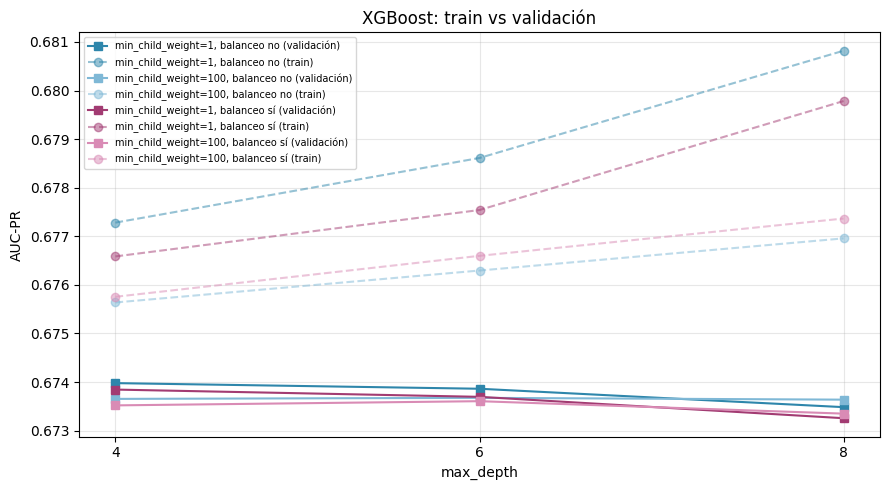

Combinaciones empatadas con el mejor AUC-PR: 12 de 12
Elegido: max_depth=4, min_child_weight=100, balanceo=sí, 917 árboles


In [7]:
UMBRAL = 0.5   # umbral por defecto, como en los papers (no se calibra)
MAX_ARBOLES = 2000

def evaluar(y_true, p, umbral=UMBRAL):
    pred = (p >= umbral).astype(int)
    return {"auc_roc": roc_auc_score(y_true, p),
            "auc_pr": average_precision_score(y_true, p),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred, zero_division=0),
            "accuracy": accuracy_score(y_true, pred)}

def modelo_xgboost(max_depth, min_child_weight, scale_pos_weight):
    # Hasta MAX_ARBOLES árboles: el early stopping se queda con la mejor iteración por AUC-PR en validación
    return XGBClassifier(n_estimators=MAX_ARBOLES, learning_rate=0.1, max_depth=max_depth,
                         min_child_weight=min_child_weight, scale_pos_weight=scale_pos_weight,
                         tree_method="hist", eval_metric="aucpr", early_stopping_rounds=50,
                         n_jobs=-1, random_state=SEMILLA)

prep = construir_preprocesador().fit(X_tr)                      # fit SOLO con train
Xtr_t, Xval_t = prep.transform(X_tr), prep.transform(X_val)    # matrices dispersas: XGBoost las usa directamente
RATIO = float((y_tr == 0).sum() / y_tr.sum())                  # negativos por cada positivo en train
print(f"Matriz de train: {Xtr_t.shape} | negativos por cada positivo en train: {RATIO:.2f}")

filas, modelos = [], {}
for depth in [4, 6, 8]:
    for mcw in [1, 100]:
        for balanceo, spw in [("no", 1.0), ("sí", RATIO)]:
            t0 = time.time()
            m = modelo_xgboost(depth, mcw, spw).fit(Xtr_t, y_tr, eval_set=[(Xval_t, y_val)], verbose=False)
            seg_fit = time.time() - t0
            p_tr, p_val = m.predict_proba(Xtr_t)[:, 1], m.predict_proba(Xval_t)[:, 1]   # con la mejor iteración
            v = evaluar(y_val, p_val)
            modelos[(depth, mcw, balanceo)] = m
            filas.append({"max_depth": depth, "min_child_weight": mcw, "balanceo": balanceo,
                          "arboles": m.best_iteration + 1,
                          "auc_pr_train": average_precision_score(y_tr, p_tr), "auc_pr_val": v["auc_pr"],
                          "auc_roc_val": v["auc_roc"],
                          "precision_val": v["precision"], "recall_val": v["recall"], "f1_val": v["f1"],
                          "accuracy_val": v["accuracy"], "seg": seg_fit})
            print(f"max_depth={depth}, min_child_weight={mcw}, balanceo={balanceo}: "
                  f"AUC-PR val {v['auc_pr']:.4f} con {m.best_iteration + 1} árboles ({seg_fit:.0f} s)")
res = pd.DataFrame(filas)
display(res.round(4))
print("El early stopping se activó en todos los modelos (ninguno llegó al límite de árboles):",
      bool((res["arboles"] <= MAX_ARBOLES - 50).all()))

fig, ax = plt.subplots(figsize=(9, 5))
colores = {(1, "no"): "#2E86AB", (100, "no"): "#7FB8D6", (1, "sí"): "#A23B72", (100, "sí"): "#D98BB5"}
for (mcw, bal), col in colores.items():
    d = res[(res.min_child_weight == mcw) & (res.balanceo == bal)]
    ax.plot(d.max_depth, d.auc_pr_val, "s-", color=col, label=f"min_child_weight={mcw}, balanceo {bal} (validación)")
    ax.plot(d.max_depth, d.auc_pr_train, "o--", color=col, alpha=.5, label=f"min_child_weight={mcw}, balanceo {bal} (train)")
ax.set_xticks([4, 6, 8]); ax.set_xlabel("max_depth"); ax.set_ylabel("AUC-PR")
ax.set_title("XGBoost: train vs validación")
ax.legend(fontsize=7); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

empates = res[res["auc_pr_val"] >= res["auc_pr_val"].max() - 0.001].copy()
mejor = empates.sort_values(["max_depth", "min_child_weight", "recall_val"], ascending=[True, False, False]).iloc[0]
print(f"Combinaciones empatadas con el mejor AUC-PR: {len(empates)} de {len(res)}")
print(f"Elegido: max_depth={mejor['max_depth']}, min_child_weight={mejor['min_child_weight']}, "
      f"balanceo={mejor['balanceo']}, {mejor['arboles']} árboles")

## 4. Modelo final y evaluación en test

El modelo final es el elegido en la sección 3, ya entrenado con train y con los árboles hasta su mejor iteración, unido a su preprocesador en un `Pipeline`, y se evalúa **una sola vez** en el test (2024–2025). Como referencia se incluye el baseline (regresión logística simple, `C=1`, sin balanceo), entrenado con los mismos datos.

In [8]:
clave = (int(mejor["max_depth"]), int(mejor["min_child_weight"]), mejor["balanceo"])
final = Pipeline([("prep", prep), ("clf", modelos[clave])])   # pasos ya ajustados con train
NOMBRE = "XGBoost balanceado" if mejor["balanceo"] == "sí" else "XGBoost"
del modelos, Xtr_t, Xval_t; gc.collect()
baseline = Pipeline([("prep", construir_preprocesador()),
                     ("clf", LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000, random_state=SEMILLA))]).fit(X_tr, y_tr)

probas_te = {NOMBRE: final.predict_proba(X_te)[:, 1],
             "RL simple (baseline)": baseline.predict_proba(X_te)[:, 1]}
metricas = pd.DataFrame({k: evaluar(y_te, p) for k, p in probas_te.items()}).T
display(metricas.round(4))
print("Prevalencia en test (AUC-PR de un clasificador al azar):", round(y_te.mean(), 4))
for k, p in probas_te.items():
    cm = confusion_matrix(y_te, (p >= UMBRAL).astype(int))
    print(f"{k}: matriz de confusión [[TN FP], [FN TP]] = {cm.tolist()} | detecta {cm[1, 1]:,} de {int(y_te.sum()):,} casos")

,auc_roc,auc_pr,precision,recall,f1,accuracy
XGBoost balanceado,0.9130,0.6818,0.3246,0.8030,0.4623,0.8727
RL simple (baseline),0.9081,0.6774,0.8204,0.4732,0.6002,0.9570


Prevalencia en test (AUC-PR de un clasificador al azar): 0.0681
XGBoost balanceado: matriz de confusión [[TN FP], [FN TP]] = [[587048, 81718], [9636, 39271]] | detecta 39,271 de 48,907 casos
RL simple (baseline): matriz de confusión [[TN FP], [FN TP]] = [[663699, 5067], [25763, 23144]] | detecta 23,144 de 48,907 casos


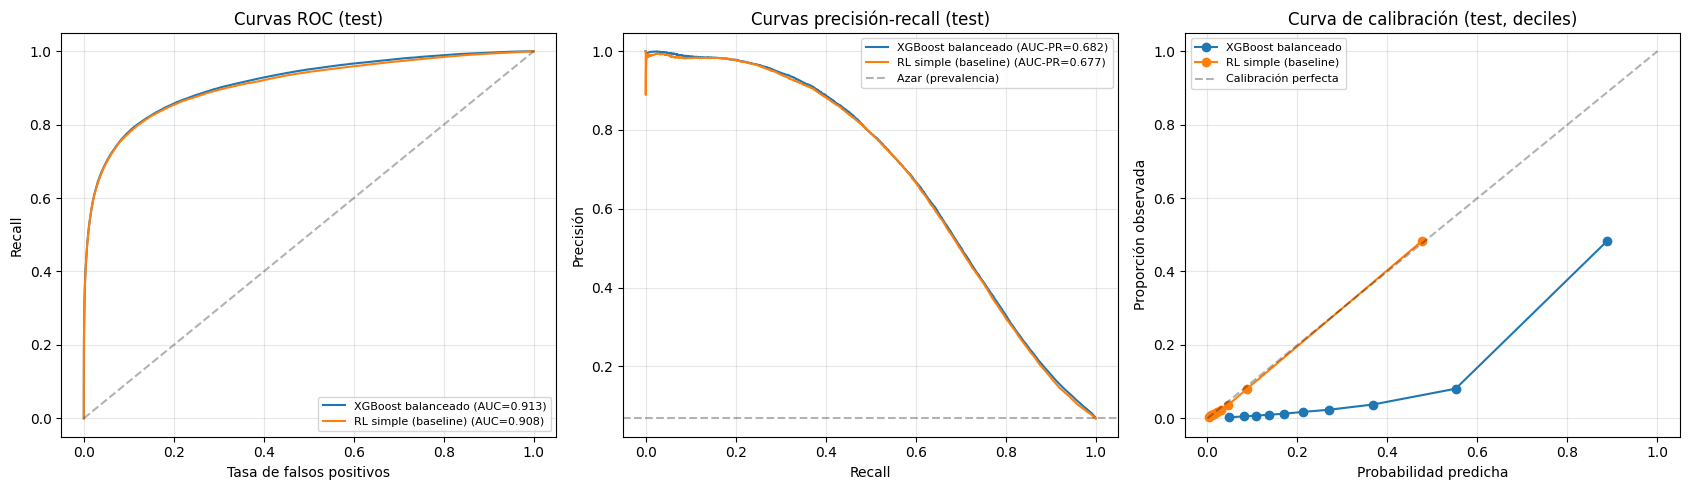

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for k, p in probas_te.items():
    fpr, tpr, _ = roc_curve(y_te, p)
    axes[0].plot(fpr, tpr, label=f"{k} (AUC={roc_auc_score(y_te, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_te, p)
    axes[1].plot(rc, pr, label=f"{k} (AUC-PR={average_precision_score(y_te, p):.3f})")
    frac, media = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
    axes[2].plot(media, frac, "o-", label=k)
axes[0].plot([0, 1], [0, 1], "k--", alpha=.3)
axes[0].set(title="Curvas ROC (test)", xlabel="Tasa de falsos positivos", ylabel="Recall")
axes[1].axhline(y_te.mean(), color="k", ls="--", alpha=.3, label="Azar (prevalencia)")
axes[1].set(title="Curvas precisión-recall (test)", xlabel="Recall", ylabel="Precisión")
axes[2].plot([0, 1], [0, 1], "k--", alpha=.3, label="Calibración perfecta")
axes[2].set(title="Curva de calibración (test, deciles)", xlabel="Probabilidad predicha", ylabel="Proporción observada")
for a in axes:
    a.legend(fontsize=8); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 5. Interpretación

Las cifras corresponden a la ejecución en local (xgboost 3.2.0, scikit-learn 1.9.1); los valores exactos están en las tablas de arriba. El baseline, reentrenado aquí, reproduce exactamente las cifras del notebook 02 (ejecutado en Colab): los datos, la partición y el preprocesamiento son los mismos, así que la comparación con los demás notebooks es válida.

**1. Los hiperparámetros casi no cambian el resultado: las 12 combinaciones quedan empatadas.** El AUC-PR en validación va de 0.6733 a 0.6740 y el AUC-ROC de 0.9088 a 0.9092, todo dentro de la tolerancia de 0.001; en el Random Forest, en cambio, `max_features` movía el AUC-PR entre 0.55 y 0.67. Hay dos motivos. Aquí cada corte puede usar las 53 columnas, mientras que en el Random Forest, con `"sqrt"`, muchos cortes no tenían disponibles las variables más informativas. Y el *early stopping* ajusta el número de árboles a cada combinación, compensando la profundidad: con `max_depth = 4` hicieron falta entre 653 y 917 árboles, con 6 entre 235 y 328, y con 8 entre 117 y 227. Los árboles profundos aprenden más en cada paso y se detienen antes, así que todas las combinaciones llegan prácticamente al mismo techo. Ninguna alcanzó el límite de 2000 árboles.

**2. El sobreajuste es leve y está controlado.** El AUC-PR de train sube con la profundidad (con `min_child_weight = 1` y sin balanceo, de 0.677 con `max_depth = 4` a 0.681 con 8), mientras que el de validación baja un poco (de 0.6740 a 0.6735): los árboles profundos empiezan a aprender detalles de train que no se repiten en validación. `min_child_weight = 100` reduce esa brecha (con `max_depth = 8`, de 0.006–0.007 a 0.003–0.004) sin cambiar el AUC-PR en validación. Aun así, la brecha más grande es pequeña frente a la del Random Forest con hojas de 10 registros (0.021): el *early stopping* detiene el modelo antes de que el sobreajuste afecte a la validación, y con 3.2 millones de registros hay poco espacio para memorizar.

**3. El balanceo cambia el punto de operación, no la discriminación.** Para cada combinación de `max_depth` y `min_child_weight`, las versiones con y sin balanceo tienen prácticamente el mismo AUC-PR en validación (diferencias de 0.0002 o menos) y el mismo AUC-ROC (0.0003 o menos). Lo que cambia es el resultado con el umbral 0.5: sin balanceo, recall ≈ 0.49 y precisión ≈ 0.81; con balanceo, recall ≈ 0.78 y precisión ≈ 0.33. Es el mismo patrón de la regresión logística balanceada (notebook 03). En Almeida et al. (2026) balancear le costó discriminación al random forest (el AUC-ROC bajó de 0.81 a 0.78); con XGBoost y estos datos ese costo no aparece.

**4. Modelo elegido: `max_depth = 4`, `min_child_weight = 100`, con balanceo y 917 árboles.** Como las 12 combinaciones empatan, decide la regla de desempate: el menor `max_depth`, luego el mayor `min_child_weight` y, entre la versión con y sin balanceo, la de mayor recall en validación (0.78 frente a 0.49). Su AUC-PR en validación (0.6735) queda a 0.0005 del mejor (0.6740, con `max_depth = 4`, `min_child_weight = 1` y sin balanceo). La regla prefiere árboles simples, pero el *early stopping* lo compensa con más árboles: el modelo elegido es el de más árboles de la grilla (917) y el de ajuste más lento (unos 12 minutos).

**5. En test, XGBoost es el modelo que mejor discrimina, por un margen pequeño.** Alcanza AUC-ROC 0.913 y AUC-PR 0.682, frente a 0.908 y 0.677 del baseline y 0.911 y 0.679 del Random Forest balanceado (notebook 05), el mejor modelo hasta ahora. Son los valores más altos de los cinco modelos, así que, con el criterio de comparación del proyecto (primero la discriminación), XGBoost pasa a ser el de mejor desempeño. Pero la ventaja sobre el baseline es de solo 0.005 en AUC-ROC y 0.004 en AUC-PR, y las curvas ROC y precisión-recall casi se superponen. La ventaja es consistente: también aparece en validación, donde incluso la peor combinación de XGBoost (AUC-PR 0.6733) supera al Random Forest elegido (0.6697) y al baseline (0.6666). Además, el modelo generaliza en el tiempo: entre validación y test, el AUC-ROC pasa de 0.9091 a 0.9130 y el AUC-PR de 0.6735 a 0.6818; como en el baseline, la subida del AUC-PR se debe sobre todo a la mayor prevalencia del test (relativo al azar baja levemente, de 10.7 a 10.0 veces).

**6. Punto de operación con el umbral 0.5.** Detecta 39 271 de 48 907 casos (recall 0.80) con 81 718 falsas alarmas, unas 2.1 por cada caso detectado (precisión 0.32, F1 0.46). Queda entre los otros dos modelos balanceados: frente a la regresión logística balanceada, con un recall casi igual (0.80 frente a 0.81), da unas 6 200 falsas alarmas menos; frente al Random Forest balanceado, detecta 471 casos más a cambio de unas 5 900 falsas alarmas más (precisión 0.32 frente a 0.34). Con el umbral fijo, estas diferencias dependen también de dónde cae el 0.5 en cada modelo; la capacidad de discriminar se compara con el AUC-ROC y el AUC-PR.

**7. Las probabilidades quedan infladas.** En el decil de mayor riesgo XGBoost predice en promedio cerca de 0.89, pero la proporción observada de bajo peso es cercana a 0.48; en el noveno decil predice cerca de 0.55 y se observa cerca de 0.08. Es el efecto esperado de `scale_pos_weight` ≈ 14.8: con la pérdida logística, ese peso hace que el modelo estime aproximadamente las odds reales multiplicadas por 14.8 (un riesgo real de 8%, con odds de 0.087, pasa a odds de 1.29, es decir, a una probabilidad de 0.56). Como en los otros modelos balanceados, para usar las probabilidades como riesgo absoluto habría que recalibrarlas; el baseline sigue bien calibrado. Una corrección simple sería dividir las odds entre 14.8 (no se probó aquí); como no cambia el orden de los registros, no afectaría el AUC-ROC ni el AUC-PR.

**8. Comparación con Ranjbar et al. (2023).** En ese estudio XGBoost fue el mejor modelo global (AUROC 0.79, accuracy 0.79, recall 0.69, F1 0.77), y la red feedforward tuvo el AUROC más alto (0.86). Aquí XGBoost también queda primero en discriminación, con un AUC-ROC mayor (0.913) y más recall (0.80), pero con un F1 menor (0.46). No son directamente comparables: Ranjbar usa 8 853 partos de Irán con 14.5% de bajo peso, variables clínicas (hipertensión, preeclampsia, anemia, antecedente de bajo peso) y validación cruzada; aquí hay 4.8 millones de nacimientos, 6.8% de prevalencia en test, solo variables del CNV y una partición temporal. El F1 bajo de este modelo viene de su precisión (0.32), que baja con el balanceo: sin balanceo, XGBoost tiene un F1 cercano a 0.61 en validación.

**9. Costo.** Ajustar la grilla tomó unos 64 minutos en local, frente a unos 35 minutos del Random Forest en Colab y unos 13 segundos del baseline, para una mejora de 0.005 en AUC-ROC y 0.004 en AUC-PR sobre el baseline. Los tiempos de entornos distintos no son directamente comparables, pero el orden de magnitud sí. Además, un modelo de 917 árboles es mucho menos interpretable que los coeficientes de una regresión logística.

## 6. Limitaciones

- **`DUR_EMB_PARTO` se conoce al momento del parto, no antes.** El encuadre es "información registrada al momento del parto, antes del pesaje"; no es una predicción prenatal.
- **Umbral fijo en 0.5**, como en los papers. Precisión, recall y F1 dependen de esa elección; AUC-ROC y AUC-PR no.
- **La prevalencia del test (6.81%) es mayor que la de train (6.32%).** Precisión y F1 en test no son directamente comparables con validación.
- **El peso tiene redondeo en 2500 g** (16 353 registros exactos), lo que mete ruido en la etiqueta justo en el umbral.
- **El test no incluye diciembre de 2025.**
- **El CNV no registra variables clínicas** (controles prenatales, anemia, hipertensión, IMC), que podrían mejorar la predicción. Tampoco registra el antecedente de bajo peso en un embarazo previo, uno de los dos predictores más importantes en Ranjbar et al. (2023).
- El *early stopping* y la elección de hiperparámetros usan la misma validación, así que el AUC-PR en validación del modelo elegido es algo optimista. El test, que no se usó para ninguna decisión de este notebook, da la estimación sin ese sesgo.
- El modelo elegido está en el borde de la grilla (`max_depth = 4`, el menor valor probado). Como todas las combinaciones empataron, no se sabe si árboles aún más simples (2 o 3 niveles) darían el mismo AUC-PR.
- No se ajustaron `learning_rate` (fijo en 0.1), el submuestreo de filas y columnas (`subsample` y `colsample_bytree` en 1) ni la regularización (`reg_lambda`, `gamma`). En boosting, una tasa menor con más árboles suele dar una mejora pequeña; con las 12 combinaciones empatadas, es poco probable que cambie la conclusión.
- Las probabilidades de XGBoost balanceado no están calibradas (sobreestiman el riesgo); para usarlas como riesgo absoluto habría que recalibrarlas.
- No se estimó la incertidumbre de las métricas (por ejemplo, con *bootstrap*). Las diferencias con los demás modelos son de milésimas (0.002 a 0.006 en AUC-ROC y 0.003 a 0.005 en AUC-PR) y hay un solo período de test, así que no se puede asegurar que la ventaja se mantenga en otros años.
- Una sola partición de validación.